In [ ]:
!pip -q install pypdf python-docx scikit-learn pandas matplotlib

In [ ]:
import re
import io
import pandas as pd
import matplotlib.pyplot as plt

from pypdf import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
job_roles = {
    "Data Analyst": [
        "python", "sql", "excel", "pandas", "numpy",
        "power bi", "statistics", "data visualization"
    ],
    "Machine Learning Engineer": [
        "python", "machine learning", "scikit-learn", "numpy",
        "pandas", "model evaluation", "fastapi", "docker"
    ],
    "AI Engineer": [
        "python", "deep learning", "llm", "apis",
        "machine learning", "pytorch", "tensorflow", "rag"
    ],
    "NLP Engineer": [
        "python", "nlp", "natural language processing",
        "transformers", "hugging face", "spacy", "pytorch"
    ],
    "Computer Vision Engineer": [
        "python", "opencv", "computer vision", "cnn",
        "deep learning", "pytorch", "tensorflow", "yolo"
    ],
    "Python Developer": [
        "python", "git", "apis", "fastapi",
        "flask", "django", "sql", "testing"
    ]
}

job_data = pd.DataFrame([
    {"Job Role": role, "Required Skills": ", ".join(skills)}
    for role, skills in job_roles.items()
])

display(job_data)
print("Number of job roles:", len(job_roles))

,Job Role,Required Skills
0,Data Analyst,"python, sql, excel, pandas, numpy, power bi, s..."
1,Machine Learning Engineer,"python, machine learning, scikit-learn, numpy,..."
2,AI Engineer,"python, deep learning, llm, apis, machine lear..."
3,NLP Engineer,"python, nlp, natural language processing, tran..."
4,Computer Vision Engineer,"python, opencv, computer vision, cnn, deep lea..."
5,Python Developer,"python, git, apis, fastapi, flask, django, sql..."


Number of job roles: 6


In [ ]:
skill_categories = {
    "Programming": [
        "python", "java", "c++", "c#", "javascript", "typescript", "r"
    ],
    "Databases": [
        "sql", "mysql", "postgresql", "sqlite", "mongodb"
    ],
    "Data Analysis": [
        "pandas", "numpy", "excel", "power bi", "tableau",
        "statistics", "data visualization"
    ],
    "Machine Learning and AI": [
        "machine learning", "deep learning", "scikit-learn",
        "tensorflow", "pytorch", "llm", "rag", "model evaluation"
    ],
    "NLP and Computer Vision": [
        "nlp", "natural language processing", "transformers",
        "hugging face", "spacy", "opencv", "computer vision", "cnn", "yolo"
    ],
    "Web and Deployment": [
        "html", "css", "react", "fastapi", "flask", "django",
        "apis", "docker", "git", "testing", "aws", ".net"
    ]
}

all_skills = sorted(
    {skill for skills in skill_categories.values() for skill in skills},
    key=len,
    reverse=True
)

print(f"Skill dictionary contains {len(all_skills)} skills.")
print(all_skills)

Skill dictionary contains 48 skills.
['natural language processing', 'data visualization', 'model evaluation', 'machine learning', 'computer vision', 'deep learning', 'scikit-learn', 'transformers', 'hugging face', 'statistics', 'typescript', 'postgresql', 'javascript', 'tensorflow', 'power bi', 'pytorch', 'tableau', 'fastapi', 'mongodb', 'testing', 'docker', 'opencv', 'sqlite', 'django', 'pandas', 'python', 'excel', 'numpy', 'spacy', 'react', 'mysql', 'flask', 'java', 'apis', 'html', 'yolo', '.net', 'cnn', 'sql', 'llm', 'aws', 'nlp', 'c++', 'css', 'git', 'rag', 'c#', 'r']


In [ ]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded. Please upload a PDF or DOCX resume.")

filename = next(iter(uploaded))
file_bytes = uploaded[filename]
lower_name = filename.lower()

if lower_name.endswith(".pdf"):
    reader = PdfReader(io.BytesIO(file_bytes))
    resume_text = "\n".join(page.extract_text() or "" for page in reader.pages)
elif lower_name.endswith(".docx"):
    document = Document(io.BytesIO(file_bytes))
    paragraphs = [p.text for p in document.paragraphs if p.text.strip()]
    table_text = [
        cell.text
        for table in document.tables
        for row in table.rows
        for cell in row.cells
    ]
    resume_text = "\n".join(paragraphs + table_text)
else:
    raise ValueError("Unsupported file. Please upload a PDF or DOCX file.")

if not resume_text.strip():
    raise ValueError(
        "No text could be extracted. Try a text-based PDF or DOCX resume."
    )

print(f"Uploaded: {filename}")
print(f"Extracted characters: {len(resume_text)}")
print("\n--- Extracted resume text preview ---\n")
print(resume_text[:4000])

Saving Samyak Vellalore Resume (1).pdf to Samyak Vellalore Resume (1).pdf
Uploaded: Samyak Vellalore Resume (1).pdf
Extracted characters: 1477

--- Extracted resume text preview ---

Samyak Vellalore
Aspiring Software Developer | Bengaluru, India
+91 99453 87960 | samyakvellalore@gmail.com
PROFESSIONAL SUMMARY
Information Science undergraduate with strong foundations in C, Python, Data Structures, and Operating Systems.
Passionate about software development, algorithmic problem solving, and continuously learning new technologies.
Seeking software development and IT internship opportunities.
EDUCATION
Ramaiah Institute of Technology, Bengaluru
B.E. in Information Science & Engineering
CGPA: 7.95/10 | Class XII: 83.1% | Class X: 94.6%
TECHNICAL SKILLS

Programming: C, Python

Core CS Fundamentals: Data Structures, Operating Systems

Tools: Visual Studio Code, GCC
PROJECTS
Akinator-Style Guessing Game (C)

Built a console-based guessing game using a decision-tree approach.

Applied d

In [ ]:
def clean_text(text):
    # Lowercase and normalize whitespace; retain useful technical symbols.
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-z0-9+#.\s/-]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

cleaned_resume = clean_text(resume_text)

print("Text cleaning complete.")
print(cleaned_resume[:2500])

Text cleaning complete.
samyak vellalore aspiring software developer bengaluru india +91 99453 87960 samyakvellalore gmail.com professional summary information science undergraduate with strong foundations in c python data structures and operating systems. passionate about software development algorithmic problem solving and continuously learning new technologies. seeking software development and it internship opportunities. education ramaiah institute of technology bengaluru b.e. in information science engineering cgpa 7.95/10 class xii 83.1 class x 94.6 technical skills programming c python core cs fundamentals data structures operating systems tools visual studio code gcc projects akinator-style guessing game c built a console-based guessing game using a decision-tree approach. applied data structures and logical branching to improve prediction accuracy. designed an interactive command-line interface. strengthened debugging algorithm design and problem-solving skills. leadership spo

In [ ]:
def contains_skill(text, skill):
    # Special handling for technical names with punctuation.
    escaped = re.escape(skill.lower())
    pattern = rf"(?<![a-z0-9]){escaped}(?![a-z0-9])"
    return re.search(pattern, text.lower()) is not None

def extract_skills(text):
    found = set()
    for skill in all_skills:
        if contains_skill(text, skill):
            found.add(skill)
    return found

resume_skills = extract_skills(cleaned_resume)

if resume_skills:
    skills_table = []
    for category, skills in skill_categories.items():
        detected = sorted(resume_skills.intersection(skills))
        if detected:
            skills_table.append({
                "Category": category,
                "Detected Skills": ", ".join(detected)
            })
    display(pd.DataFrame(skills_table))
else:
    print("No dictionary skills detected. Check extracted text or expand the skill dictionary.")

print(f"\nTotal detected skills: {len(resume_skills)}")

,Category,Detected Skills
0,Programming,"java, python"



Total detected skills: 2


In [ ]:
role_documents = {
    role: " ".join(skills)
    for role, skills in job_roles.items()
}

documents = [cleaned_resume] + list(role_documents.values())

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
tfidf_matrix = vectorizer.fit_transform(documents)

similarities = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:]
).flatten()

similarity_results = pd.DataFrame({
    "Job Role": list(role_documents.keys()),
    "Similarity Score (%)": (similarities * 100).round(2)
}).sort_values("Similarity Score (%)", ascending=False).reset_index(drop=True)

display(similarity_results)
print("Similarity scores calculated.")

,Job Role,Similarity Score (%)
0,Data Analyst,3.34
1,AI Engineer,1.28
2,Computer Vision Engineer,0.82
3,Machine Learning Engineer,0.76
4,Python Developer,0.43
5,NLP Engineer,0.37


Similarity scores calculated.


In [ ]:
top_three = similarity_results.head(3)

print("TOP THREE RECOMMENDED ROLES")
for rank, row in enumerate(top_three.itertuples(index=False), start=1):
    print(f"{rank}. {row[0]} — {row[1]:.2f}% similarity")

print("\nReminder: these scores measure text similarity, not probability of employment.")

TOP THREE RECOMMENDED ROLES
1. Data Analyst — 3.34% similarity
2. AI Engineer — 1.28% similarity
3. Computer Vision Engineer — 0.82% similarity

Reminder: these scores measure text similarity, not probability of employment.


In [ ]:
selected_role = "Machine Learning Engineer"  # Change this to another role

required_skills = set(job_roles[selected_role])
skills_found = resume_skills.intersection(required_skills)
skills_not_detected = required_skills - resume_skills

coverage = (
    len(skills_found) / len(required_skills) * 100
    if required_skills else 0
)

print("Selected role:", selected_role)
print(f"Required-skill coverage: {coverage:.1f}%")
print("\nSkills detected:")
print(", ".join(sorted(skills_found)) if skills_found else "None detected")

print("\nRequired skills not detected:")
print(", ".join(sorted(skills_not_detected)) if skills_not_detected else "None")

Selected role: Machine Learning Engineer
Required-skill coverage: 12.5%

Skills detected:
python

Required skills not detected:
docker, fastapi, machine learning, model evaluation, numpy, pandas, scikit-learn


In [ ]:
learning_resources = {
    "fastapi": ("FastAPI fundamentals", "Build a small REST API."),
    "docker": ("Docker fundamentals", "Containerize a Python application."),
    "scikit-learn": ("Scikit-learn practice", "Build and evaluate a baseline model."),
    "machine learning": ("Machine learning foundations", "Train and evaluate a small model."),
    "python": ("Python programming", "Complete a small automation project."),
    "sql": ("SQL querying", "Practice joins, grouping, and subqueries."),
    "numpy": ("NumPy fundamentals", "Practice array operations."),
    "pandas": ("Pandas data analysis", "Clean and analyze a CSV dataset."),
    "tensorflow": ("TensorFlow fundamentals", "Build a simple neural network."),
    "pytorch": ("PyTorch fundamentals", "Train a small neural network."),
    "deep learning": ("Deep learning foundations", "Study neural networks and evaluation."),
    "nlp": ("NLP foundations", "Build a text classification baseline."),
    "transformers": ("Transformer models", "Explore a pretrained text model."),
    "hugging face": ("Hugging Face tools", "Run a pretrained model pipeline."),
    "power bi": ("Power BI dashboards", "Create a dashboard from a dataset."),
    "excel": ("Excel analysis", "Build a pivot table and chart."),
    "opencv": ("OpenCV fundamentals", "Build a basic image-processing demo."),
    "computer vision": ("Computer vision foundations", "Explore image classification."),
    "yolo": ("YOLO object detection", "Run an object-detection demo."),
    "apis": ("API fundamentals", "Call an API and process its response."),
    "git": ("Git fundamentals", "Version-control a small project."),
    "testing": ("Software testing", "Write tests for key functions.")
}

roadmap = []
for skill in sorted(skills_not_detected):
    topic, task = learning_resources.get(
        skill,
        (f"Learn {skill}", f"Complete a small practical exercise using {skill}.")
    )
    roadmap.append({
        "Skill not detected": skill,
        "Learning topic": topic,
        "Suggested practical task": task
    })

if roadmap:
    display(pd.DataFrame(roadmap))
else:
    print("No skill gaps detected for this role by the current dictionary.")

,Skill not detected,Learning topic,Suggested practical task
0,docker,Docker fundamentals,Containerize a Python application.
1,fastapi,FastAPI fundamentals,Build a small REST API.
2,machine learning,Machine learning foundations,Train and evaluate a small model.
3,model evaluation,Learn model evaluation,Complete a small practical exercise using mode...
4,numpy,NumPy fundamentals,Practice array operations.
5,pandas,Pandas data analysis,Clean and analyze a CSV dataset.
6,scikit-learn,Scikit-learn practice,Build and evaluate a baseline model.


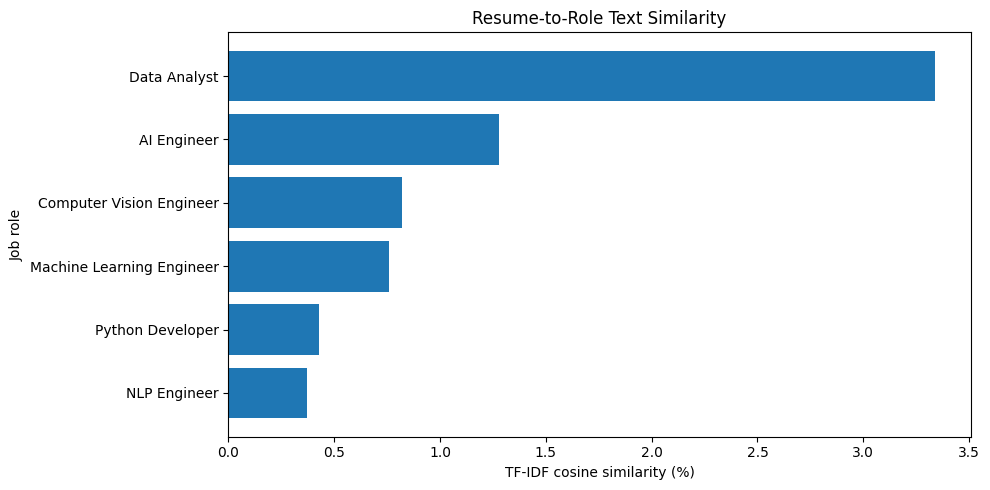

In [ ]:
plot_data = similarity_results.sort_values(
    "Similarity Score (%)", ascending=True
)

plt.figure(figsize=(10, 5))
plt.barh(plot_data["Job Role"], plot_data["Similarity Score (%)"])
plt.xlabel("TF-IDF cosine similarity (%)")
plt.ylabel("Job role")
plt.title("Resume-to-Role Text Similarity")
plt.tight_layout()
plt.show()

In [ ]:
report_lines = [
    "AI Resume Analyzer - Analysis Summary",
    f"Uploaded filename: {filename}",
    f"Detected skills: {', '.join(sorted(resume_skills))}",
    f"Selected role: {selected_role}",
    f"Required-skill coverage: {coverage:.1f}%",
    f"Skills detected for selected role: {', '.join(sorted(skills_found))}",
    f"Skills not detected for selected role: {', '.join(sorted(skills_not_detected))}",
    "",
    "Top role similarity scores:"
]
for row in top_three.itertuples(index=False):
    report_lines.append(f"{row[0]}: {row[1]:.2f}%")

report_text = "\n".join(report_lines)
print(report_text)

similarity_results.to_csv("role_similarity_report.csv", index=False)
print("\nSaved role_similarity_report.csv")

# Uncomment the next two lines in Colab to download the CSV:
# from google.colab import files
# files.download("role_similarity_report.csv")

AI Resume Analyzer - Analysis Summary
Uploaded filename: Samyak Vellalore Resume (1).pdf
Detected skills: java, python
Selected role: Machine Learning Engineer
Required-skill coverage: 12.5%
Skills detected for selected role: python
Skills not detected for selected role: docker, fastapi, machine learning, model evaluation, numpy, pandas, scikit-learn

Top role similarity scores:
Data Analyst: 3.34%
AI Engineer: 1.28%
Computer Vision Engineer: 0.82%

Saved role_similarity_report.csv
